# 05 — Aggregate Results

Chạy notebook này **sau khi 4 notebook model hoàn tất**.

Notebook:
- tổng hợp Dev/Test metrics;
- tạo bảng 4 model × 2 task;
- per-class metrics;
- confusion matrix model tốt nhất;
- learning curves;
- length analysis;
- error cases thật từ Test predictions;
- environment log;
- final QA;
- tạo ZIP nhẹ để gửi kiểm tra/báo cáo.

Không train model trong notebook này.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
!pip -q install "pandas==2.2.2" "scikit-learn==1.6.1" "seaborn==0.13.2" "tabulate==0.9.0"

Mounted at /content/drive


In [2]:
import json, shutil, sys, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

ROOT = Path("/content/drive/MyDrive/DS108_Toxic_4Models")
ARTIFACT_DIR = ROOT / "artifacts"
RESULT_DIR = ROOT / "results"
PRED_DIR = RESULT_DIR / "predictions"
CM_DIR = RESULT_DIR / "confusion_matrices"
FIG_DIR = ROOT / "figures"
REPORT_DIR = ROOT / "report"
DATA_DIR = ROOT / "data"

for p in [RESULT_DIR, PRED_DIR, CM_DIR, FIG_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DISPLAY = {
    "textcnn": "TextCNN",
    "phobert": "PhoBERT",
    "videberta": "ViDeBERTa",
    "xlmr": "XLM-R",
}

TASKS = {
    "task1": {"label2id": {"NON-TOXIC": 0, "TOXIC": 1}},
    "task2": {"label2id": {"EXPLICIT": 0, "IMPLICIT": 1}},
}

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def compute_metrics(y, yp):
    acc = accuracy_score(y, yp)
    mp, mr, mf, _ = precision_recall_fscore_support(y, yp, average="macro", zero_division=0)
    _, _, wf, _ = precision_recall_fscore_support(y, yp, average="weighted", zero_division=0)
    return {
        "accuracy": float(acc),
        "macro_precision": float(mp),
        "macro_recall": float(mr),
        "macro_f1": float(mf),
        "weighted_f1": float(wf),
    }

In [3]:
dev_rows = []
test_by_task = {"task1": [], "task2": []}
per_class_rows = []

for model_key in ["textcnn", "phobert", "videberta", "xlmr"]:
    for task in ["task1", "task2"]:
        out = ARTIFACT_DIR / model_key / task
        dev_path = out / "dev_metrics.json"
        test_path = out / "test_metrics.json"
        cfg_path = out / "experiment_config.json"
        pc_path = out / "classification_report.csv"

        assert dev_path.exists(), f"Missing {dev_path}"
        assert test_path.exists(), f"Missing {test_path}"
        assert cfg_path.exists(), f"Missing {cfg_path}"
        assert pc_path.exists(), f"Missing {pc_path}"

        dm = load_json(dev_path)
        tm = load_json(test_path)
        cfg = load_json(cfg_path)

        dev_rows.append({
            "Model": DISPLAY[model_key],
            "Task": task,
            "Best_Epoch": cfg["best_epoch"],
            "Accuracy": dm["accuracy"],
            "Macro_Precision": dm["macro_precision"],
            "Macro_Recall": dm["macro_recall"],
            "Macro_F1": dm["macro_f1"],
            "Weighted_F1": dm["weighted_f1"],
            "PR_AUC_Positive": dm.get("pr_auc_positive_class"),
            "Training_Time_Seconds": cfg["training_time_seconds"],
        })

        test_by_task[task].append({
            "Model": DISPLAY[model_key],
            "Accuracy": tm["accuracy"],
            "Macro_Precision": tm["macro_precision"],
            "Macro_Recall": tm["macro_recall"],
            "Macro_F1": tm["macro_f1"],
            "Weighted_F1": tm["weighted_f1"],
            "PR_AUC_Positive": tm.get("pr_auc_positive_class"),
        })

        pc = pd.read_csv(pc_path)
        pc.insert(0, "task", task)
        pc.insert(0, "model", DISPLAY[model_key])
        per_class_rows.append(pc)

dev_results = pd.DataFrame(dev_rows)
task1_results = pd.DataFrame(test_by_task["task1"])
task2_results = pd.DataFrame(test_by_task["task2"])
per_class_results = pd.concat(per_class_rows, ignore_index=True)

dev_results.to_csv(RESULT_DIR / "dev_results.csv", index=False)
task1_results.to_csv(RESULT_DIR / "test_results_task1.csv", index=False)
task2_results.to_csv(RESULT_DIR / "test_results_task2.csv", index=False)
per_class_results.to_csv(RESULT_DIR / "per_class_metrics.csv", index=False)

print("TASK 1")
display(task1_results.sort_values("Macro_F1", ascending=False))

print("TASK 2")
display(task2_results.sort_values("Macro_F1", ascending=False))

print("DEV")
display(dev_results)

TASK 1


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,PR_AUC_Positive
1,PhoBERT,0.917608,0.812940,0.778627,0.794342,0.915220,0.694329
3,XLM-R,0.908773,0.784066,0.789070,0.786535,0.909172,0.681852
0,TextCNN,0.895624,0.754402,0.730781,0.741718,0.893084,0.578205
2,ViDeBERTa,0.765769,0.553036,0.578166,0.557502,0.787975,0.188786


TASK 2


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,PR_AUC_Positive
3,XLM-R,0.837884,0.686486,0.712442,0.697766,0.843152,0.462791
1,PhoBERT,0.800341,0.651279,0.709698,0.669158,0.816339,0.501587
0,TextCNN,0.715017,0.600358,0.674140,0.601258,0.751725,0.350189
2,ViDeBERTa,0.810580,0.540871,0.523140,0.523022,0.784668,0.227430


DEV


,Model,Task,Best_Epoch,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,PR_AUC_Positive,Training_Time_Seconds
0,TextCNN,task1,8,0.897678,0.760272,0.729739,0.743575,0.894492,0.563061,1827.467971
1,TextCNN,task2,1,0.711604,0.578053,0.628814,0.578856,0.745901,0.262317,14.458578
2,PhoBERT,task1,5,0.919252,0.815519,0.787662,0.800657,0.917388,0.693042,2334.457076
3,PhoBERT,task2,3,0.810580,0.669336,0.739767,0.690509,0.826699,0.428817,222.259548
4,ViDeBERTa,task1,2,0.759400,0.548532,0.573073,0.551887,0.783397,0.173602,2670.098660
5,ViDeBERTa,task2,6,0.786689,0.524492,0.518767,0.519442,0.772624,0.181267,635.514155
6,XLM-R,task1,6,0.910006,0.786436,0.795663,0.790939,0.910719,0.700684,3910.424778
7,XLM-R,task2,9,0.819113,0.648937,0.662930,0.655256,0.823168,0.373724,597.483137


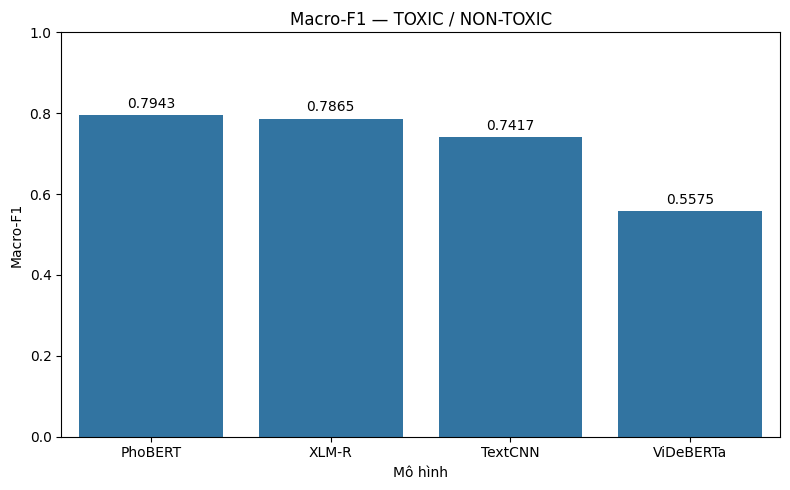

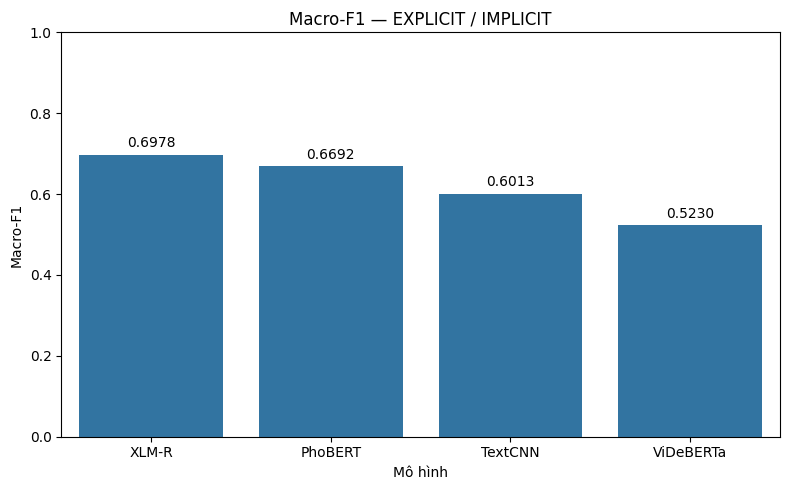

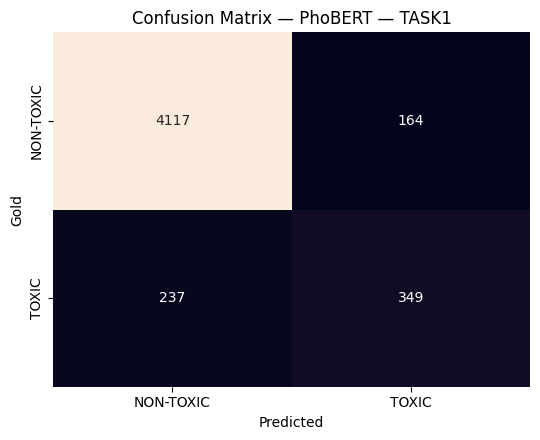

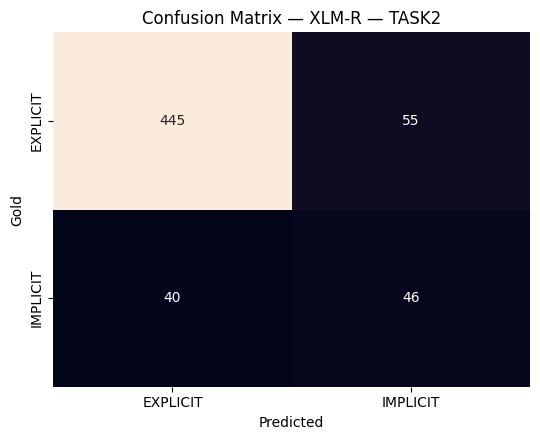

In [4]:
def model_key(display_name):
    return {v: k for k, v in DISPLAY.items()}[display_name]

def plot_comparison(df, title, filename):
    d = df.sort_values("Macro_F1", ascending=False)
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=d, x="Model", y="Macro_F1")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Mô hình")
    ax.set_ylabel("Macro-F1")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.4f", padding=3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

plot_comparison(task1_results, "Macro-F1 — TOXIC / NON-TOXIC", "01_model_comparison_task1.png")
plot_comparison(task2_results, "Macro-F1 — EXPLICIT / IMPLICIT", "02_model_comparison_task2.png")

for task, res, filename in [
    ("task1", task1_results, "03_confusion_matrix_task1_best.png"),
    ("task2", task2_results, "04_confusion_matrix_task2_best.png"),
]:
    best_name = res.sort_values("Macro_F1", ascending=False).iloc[0]["Model"]
    key = model_key(best_name)
    cm = pd.read_csv(CM_DIR / f"{key}_{task}_cm.csv", index_col=0)

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="g", cbar=False)
    plt.title(f"Confusion Matrix — {best_name} — {task.upper()}")
    plt.xlabel("Predicted")
    plt.ylabel("Gold")
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

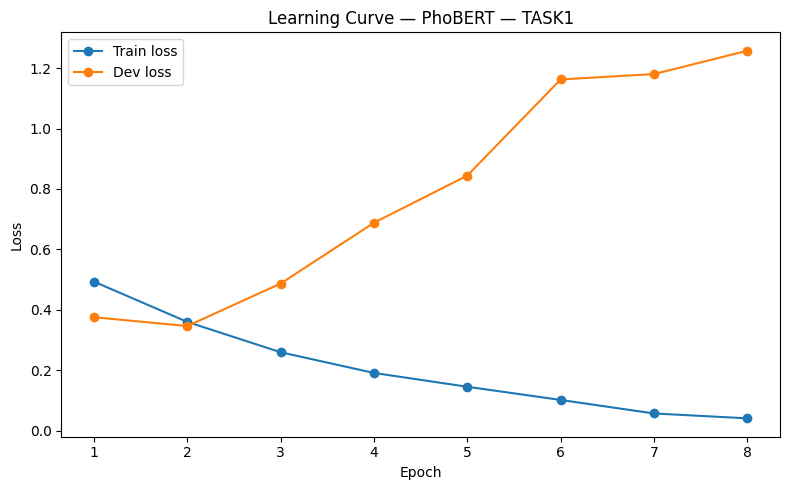

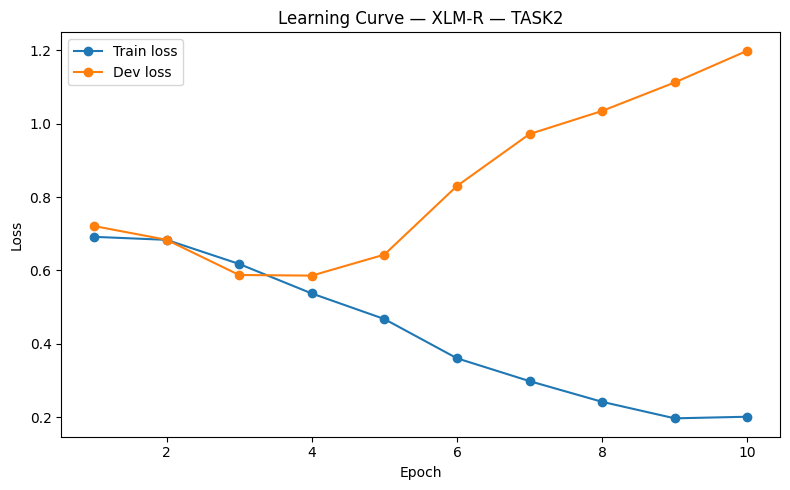

In [5]:
for task, res, filename in [
    ("task1", task1_results, "07_learning_curve_task1_best.png"),
    ("task2", task2_results, "08_learning_curve_task2_best.png"),
]:
    best_name = res.sort_values("Macro_F1", ascending=False).iloc[0]["Model"]
    key = model_key(best_name)
    hist = pd.read_csv(ARTIFACT_DIR / key / task / "training_history.csv")

    plt.figure(figsize=(8, 5))
    plt.plot(hist["epoch"], hist["train_loss"], marker="o", label="Train loss")
    plt.plot(hist["epoch"], hist["dev_loss"], marker="o", label="Dev loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Learning Curve — {best_name} — {task.upper()}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

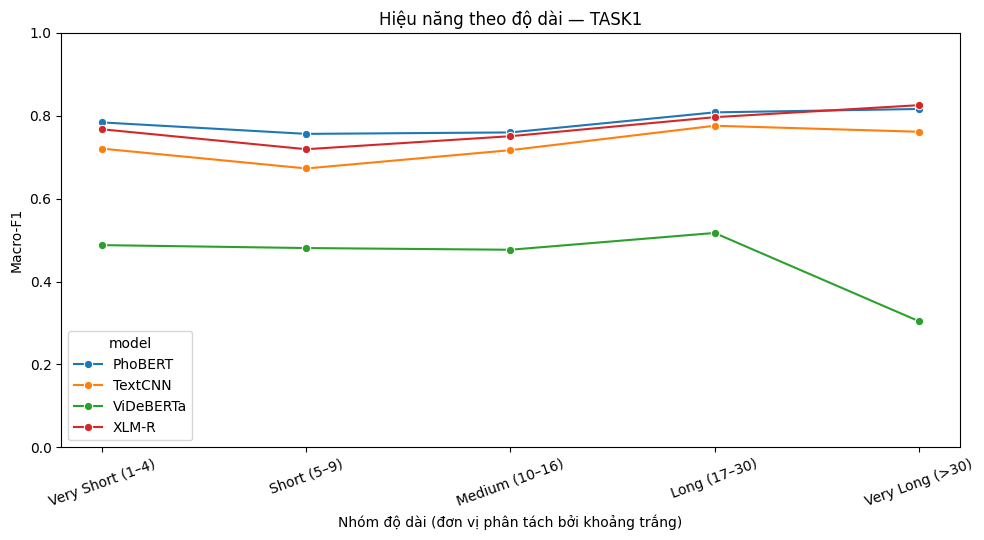

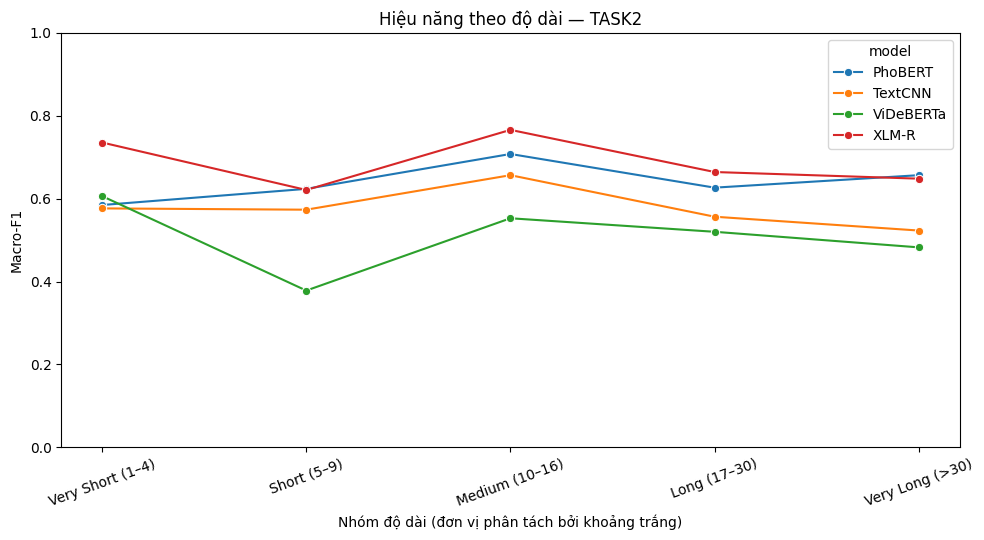

,model,task,length_group,support,accuracy,macro_f1
0,TextCNN,task1,Long (17–30),901,0.874584,0.775840
1,TextCNN,task1,Medium (10–16),1003,0.890329,0.716946
2,TextCNN,task1,Short (5–9),1311,0.910755,0.672807
3,TextCNN,task1,Very Long (>30),830,0.859036,0.761365
4,TextCNN,task1,Very Short (1–4),822,0.937956,0.720630
5,TextCNN,task2,Long (17–30),160,0.706250,0.556368
6,TextCNN,task2,Medium (10–16),128,0.695312,0.656553
7,TextCNN,task2,Short (5–9),97,0.628866,0.573314
8,TextCNN,task2,Very Long (>30),162,0.802469,0.523003
9,TextCNN,task2,Very Short (1–4),39,0.666667,0.576441


In [6]:
def length_group(n):
    if n <= 4: return "Very Short (1–4)"
    if n <= 9: return "Short (5–9)"
    if n <= 16: return "Medium (10–16)"
    if n <= 30: return "Long (17–30)"
    return "Very Long (>30)"

length_rows = []

for key in ["textcnn", "phobert", "videberta", "xlmr"]:
    for task in ["task1", "task2"]:
        p = pd.read_csv(PRED_DIR / f"{key}_{task}.csv")
        p["ws_count"] = p["comment"].astype(str).map(lambda x: len(x.split()))
        p["length_group"] = p["ws_count"].map(length_group)
        l2i = TASKS[task]["label2id"]
        p["gold_id"] = p["gold_label"].map(l2i)
        p["pred_id"] = p["predicted_label"].map(l2i)

        for group, g in p.groupby("length_group"):
            m = compute_metrics(g["gold_id"], g["pred_id"])
            length_rows.append({
                "model": DISPLAY[key],
                "task": task,
                "length_group": group,
                "support": len(g),
                "accuracy": m["accuracy"],
                "macro_f1": m["macro_f1"],
            })

length_results = pd.DataFrame(length_rows)
length_results.to_csv(RESULT_DIR / "length_analysis.csv", index=False)

order = [
    "Very Short (1–4)",
    "Short (5–9)",
    "Medium (10–16)",
    "Long (17–30)",
    "Very Long (>30)",
]

for task, filename in [
    ("task1", "05_length_analysis_task1.png"),
    ("task2", "06_length_analysis_task2.png"),
]:
    d = length_results[length_results["task"].eq(task)].copy()
    d["length_group"] = pd.Categorical(d["length_group"], categories=order, ordered=True)
    d = d.sort_values(["length_group", "model"])

    plt.figure(figsize=(10, 5.5))
    sns.lineplot(data=d, x="length_group", y="macro_f1", hue="model", marker="o")
    plt.ylim(0, 1)
    plt.xlabel("Nhóm độ dài (đơn vị phân tách bởi khoảng trắng)")
    plt.ylabel("Macro-F1")
    plt.title(f"Hiệu năng theo độ dài — {task.upper()}")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

display(length_results)

In [7]:
gold = pd.read_csv(DATA_DIR / "gold_standard_final_48670.csv")
error_rows = []

for task, res in [("task1", task1_results), ("task2", task2_results)]:
    best_name = res.sort_values("Macro_F1", ascending=False).iloc[0]["Model"]
    key = model_key(best_name)
    p = pd.read_csv(PRED_DIR / f"{key}_{task}.csv")
    p = p.merge(gold[["row_id", "evidence"]], on="row_id", how="left", validate="one_to_one")

    if task == "task1":
        groups = [
            ("False Positive", "NON-TOXIC", "TOXIC"),
            ("False Negative", "TOXIC", "NON-TOXIC"),
        ]
    else:
        groups = [
            ("EXPLICIT → IMPLICIT", "EXPLICIT", "IMPLICIT"),
            ("IMPLICIT → EXPLICIT", "IMPLICIT", "EXPLICIT"),
        ]

    for error_type, gold_label, pred_label in groups:
        g = p[
            p["gold_label"].eq(gold_label)
            & p["predicted_label"].eq(pred_label)
        ].copy()

        pred_id = TASKS[task]["label2id"][pred_label]
        g["confidence"] = g[f"prob_class_{pred_id}"]
        g = g.sort_values("confidence", ascending=False).head(5)

        for _, r in g.iterrows():
            error_rows.append({
                "model": best_name,
                "task": task,
                "error_type": error_type,
                "row_id": r["row_id"],
                "comment": r["comment"],
                "gold_label": r["gold_label"],
                "predicted_label": r["predicted_label"],
                "confidence": r["confidence"],
                "evidence": r["evidence"],
                "analysis": "",
            })

error_cases = pd.DataFrame(error_rows)
error_cases.to_csv(RESULT_DIR / "error_cases.csv", index=False)
display(error_cases)

,model,task,error_type,row_id,comment,gold_label,predicted_label,confidence,evidence,analysis
0,PhoBERT,task1,False Positive,24538,Trong khi đó 2 công ti thổ tả google và apple ...,NON-TOXIC,TOXIC,0.998617,Không có căn cứ công kích người hay nhóm người...,
1,PhoBERT,task1,False Positive,48091,Thật ra bà chị này ai đọc qua cũng biết là nó ...,NON-TOXIC,TOXIC,0.998371,Không có căn cứ công kích người hay nhóm người...,
2,PhoBERT,task1,False Positive,27254,"Canh bạc thôi my fen được ăn cả, ngã về 0 tàn ...",NON-TOXIC,TOXIC,0.998367,Không có căn cứ công kích người hay nhóm người...,
3,PhoBERT,task1,False Positive,41454,Tư duy của một thằng được đào tạo dưới mái trư...,NON-TOXIC,TOXIC,0.998335,Phê bình tư duy hệ thống.,
4,PhoBERT,task1,False Positive,38910,"Ở đâu cũng có anh hùng, ở đâu cũng có kẻ khùng...",NON-TOXIC,TOXIC,0.998283,Không có căn cứ công kích người hay nhóm người...,
5,PhoBERT,task1,False Negative,44727,Alo Vietnam Meme collection à? ờ anh chào Viet...,TOXIC,NON-TOXIC,0.999255,Đe dọa cho người tới nhà một cá nhân theo kiểu...,
6,PhoBERT,task1,False Negative,8113,:)) C rep xong c có bị quê k,TOXIC,NON-TOXIC,0.999246,"Dùng mỉa mai, ám chỉ, ví von hoặc khuôn mẫu hó...",
7,PhoBERT,task1,False Negative,48317,Mở đầu thật là Niger,TOXIC,NON-TOXIC,0.999227,"Sử dụng từ ngữ xúc phạm, thô tục hoặc miệt thị...",
8,PhoBERT,task1,False Negative,3461,Công ty loại bỏ đc 1 đống rác và thu về bầu tr...,TOXIC,NON-TOXIC,0.999198,Công kích hoặc hạ thấp trực tiếp người hay nhó...,
9,PhoBERT,task1,False Negative,31621,Ủng hộ Mod Mấy thành phần này không có giá trị...,TOXIC,NON-TOXIC,0.999186,Hạ thấp một nhóm người là không có giá trị thả...,


In [8]:
# Environment + report metrics
import sklearn, transformers

environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "sklearn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "seed": 42,
}

(ROOT / "environment.json").write_text(
    json.dumps(environment, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

report_metrics = {
    "task1": task1_results.to_dict(orient="records"),
    "task2": task2_results.to_dict(orient="records"),
    "dev": dev_results.to_dict(orient="records"),
    "environment": environment,
}
(REPORT_DIR / "report_metrics.json").write_text(
    json.dumps(report_metrics, ensure_ascii=False, indent=2),
    encoding="utf-8"
)
display(environment)

{'python': '3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.35',
 'torch': '2.11.0+cpu',
 'transformers': '5.13.1',
 'sklearn': '1.6.1',
 'pandas': '2.2.2',
 'numpy': '2.0.2',
 'cuda': None,
 'gpu': 'CPU',
 'seed': 42}

In [9]:
expected_models = {"TextCNN", "PhoBERT", "ViDeBERTa", "XLM-R"}

qa = {
    "task1_has_4_models": set(task1_results["Model"]) == expected_models,
    "task2_has_4_models": set(task2_results["Model"]) == expected_models,
    "eight_predictions": all(
        (PRED_DIR / f"{m}_{t}.csv").exists()
        for m in ["textcnn", "phobert", "videberta", "xlmr"]
        for t in ["task1", "task2"]
    ),
    "eight_confusion_matrices": all(
        (CM_DIR / f"{m}_{t}_cm.csv").exists()
        for m in ["textcnn", "phobert", "videberta", "xlmr"]
        for t in ["task1", "task2"]
    ),
    "eight_training_histories": all(
        (ARTIFACT_DIR / m / t / "training_history.csv").exists()
        for m in ["textcnn", "phobert", "videberta", "xlmr"]
        for t in ["task1", "task2"]
    ),
    "per_class_metrics": (RESULT_DIR / "per_class_metrics.csv").exists(),
    "length_analysis": (RESULT_DIR / "length_analysis.csv").exists(),
    "error_cases": (RESULT_DIR / "error_cases.csv").exists(),
}

qa_df = pd.DataFrame([{"check": k, "pass": bool(v)} for k, v in qa.items()])
display(qa_df)

(RESULT_DIR / "final_qa.json").write_text(
    json.dumps(qa, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("FINAL QA PASS:", all(qa.values()))

,check,pass
0,task1_has_4_models,True
1,task2_has_4_models,True
2,eight_predictions,True
3,eight_confusion_matrices,True
4,eight_training_histories,True
5,per_class_metrics,True
6,length_analysis,True
7,error_cases,True


FINAL QA PASS: True


In [10]:
# ZIP nhẹ để tải về; checkpoint lớn vẫn giữ trên Drive.
LITE = Path("/content/DS108_4Models_Results_Lite")
if LITE.exists():
    shutil.rmtree(LITE)
LITE.mkdir(parents=True)

def cp(src, dst):
    src, dst = Path(src), Path(dst)
    if not src.exists():
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    if src.is_dir():
        shutil.copytree(src, dst, dirs_exist_ok=True)
    else:
        shutil.copy2(src, dst)

cp(ROOT / "data_splits", LITE / "data_splits")
cp(ROOT / "results", LITE / "results")
cp(ROOT / "figures", LITE / "figures")
cp(ROOT / "report", LITE / "report")
cp(ROOT / "environment.json", LITE / "environment.json")

for m in ["textcnn", "phobert", "videberta", "xlmr"]:
    for t in ["task1", "task2"]:
        src = ARTIFACT_DIR / m / t
        dst = LITE / "artifacts" / m / t
        for fname in [
            "experiment_config.json",
            "dev_metrics.json",
            "test_metrics.json",
            "training_history.csv",
            "classification_report.csv",
        ]:
            cp(src / fname, dst / fname)

archive_base = "/content/DS108_4Models_Results_Lite"
zip_path = Path(archive_base + ".zip")
if zip_path.exists():
    zip_path.unlink()

shutil.make_archive(
    archive_base,
    "zip",
    root_dir=str(LITE.parent),
    base_dir=LITE.name
)

print("Created:", zip_path)

from google.colab import files
files.download(str(zip_path))

Created: /content/DS108_4Models_Results_Lite.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>